# Projet PAD — Évolution de l'accès à un fournisseur habituel de soins (2015-2022)

**Projet** : Évolution de l'accès à un fournisseur habituel de soins de santé au Canada (2015-2022)

**Équipe** : Fatima Zohra Aboudeine · Safaa Namane · Badr Kabbadj · Mohamed Ali Alaoui

**Source** : Statistique Canada, tableau 13-10-0096-16 (ESCC)

**Structure du notebook (selon le backlog Jira)**

| Epic | Contenu |
|---|---|
| 1 | Portrait de l'accès dans le temps et par région |
| 2 | Comprendre les différences et leurs facteurs |
| 3 | Mesurer l'impact de la COVID-19 et l'après-COVID |
| 4 | Communiquer les résultats et recommander |


# 1. Portrait de l'accès dans le temps et par région


## 1.1. Préparer et structurer la table analytique


### Préparation de l'environnement


In [1]:
%pip install missingno

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno

### Spike : Exploration et validation de la structure du tableau Statistique Canada (13-10-0096-16)


#### Chargement et premier regard sur le fichier brut


In [3]:
df_raw = pd.read_csv('../data/13100096.csv', encoding="utf-8", low_memory=False)
df = df_raw.copy()
df.shape

(327165, 18)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 327165 entries, 0 to 327164
Data columns (total 18 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   REF_DATE         327165 non-null  int64  
 1   GEO              327165 non-null  str    
 2   DGUID            300890 non-null  str    
 3   Age group        327165 non-null  str    
 4   Sex              327165 non-null  str    
 5   Indicators       327165 non-null  str    
 6   Characteristics  327165 non-null  str    
 7   UOM              327165 non-null  str    
 8   UOM_ID           327165 non-null  int64  
 9   SCALAR_FACTOR    327165 non-null  str    
 10  SCALAR_ID        327165 non-null  int64  
 11  VECTOR           327165 non-null  str    
 12  COORDINATE       327165 non-null  str    
 13  VALUE            248292 non-null  float64
 14  STATUS           136323 non-null  str    
 15  SYMBOL           0 non-null       float64
 16  TERMINATED       31950 non-null   str    
 17  DE

In [5]:
df.sample()

,REF_DATE,GEO,DGUID,Age group,Sex,Indicators,Characteristics,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
204023,2020,Nova Scotia,2016A000212,50 to 64 years,Both sexes,"Life satisfaction, satisfied or very satisfied","High 95% confidence interval, number of persons",Number,223,units,0,v110799718,4.5.1.24.3,196500.0,NaN,NaN,NaN,0


**Dictionnaire des variables du fichier brut**

| # | Variable | Type | Ce qu'elle représente | Décision prévue (à confirmer au ticket 21) |
|---|---|---|---|---|
| 1 | `REF_DATE` | entier | Année de référence de l'enquête | Garder (`annee`) |
| 2 | `GEO` | texte | Zone géographique | Garder (`geographie`) |
| 3 | `DGUID` | texte | Identifiant géographique unique de StatCan | Garder pour la jointure avec la carte (ticket 32) |
| 4 | `Age group` | texte | Groupe d'âge de la population | Garder (`age`) |
| 5 | `Sex` | texte | Sexe | Garder (`sexe`) |
| 6 | `Indicators` | texte | Indicateur de santé mesuré (32 sujets) | Une seule valeur après filtre : retirer de la table analytique |
| 7 | `Characteristics` | texte | Nature de la mesure de la ligne (6 estimations + 3 drapeaux) | Garder (sert au pivot) |
| 8 | `UOM` | texte | Unité de mesure | Retirer (déduite de `Characteristics`) |
| 9 | `UOM_ID` | entier | Code numérique de l'unité | Retirer |
| 10 | `SCALAR_FACTOR` | texte | Facteur d'échelle des valeurs | Retirer (constante : « units ») |
| 11 | `SCALAR_ID` | entier | Code du facteur d'échelle | Retirer (constante : 0) |
| 12 | `VECTOR` | texte | Identifiant de la série chronologique StatCan | Retirer (identifiant technique) |
| 13 | `COORDINATE` | texte | Position de la série dans le cube (code de chaque dimension) | Retirer (identifiant technique) |
| 14 | `VALUE` | décimal | La valeur mesurée (nombre de personnes, pourcentage, borne d'IC, ou code du drapeau) | Garder (`valeur`, puis colonnes du pivot) |
| 15 | `STATUS` | texte | Symbole de qualité de la valeur | Garder (`qualite`) |
| 16 | `SYMBOL` | décimal | Entièrement vide | Retirer |
| 17 | `TERMINATED` | texte | Marque une série que StatCan a arrêtée de mettre à jour | Garder comme information (à vérifier) |
| 18 | `DECIMALS` | entier | Nombre de décimales publié | Retirer (déduite de `UOM`) |

**Granularité** : une ligne = une année × une géographie × un groupe d'âge × un sexe × un indicateur × une caractéristique.

#### Choix de l'indicateur


In [6]:
(df["Indicators"].value_counts(normalize=True) * 100).round(2)

Indicators
Influenza immunization in the past 12 months                                               3.91
Perceived health, very good or excellent                                                   3.85
Perceived health, fair or poor                                                             3.85
Perceived mental health, very good or excellent                                            3.85
Perceived mental health, fair or poor                                                      3.85
Perceived life stress, most days quite a bit or extremely stressful                        3.85
Arthritis (15 years and over)                                                              3.85
Diabetes                                                                                   3.85
Asthma                                                                                     3.85
Chronic obstructive pulmonary disease (COPD; 35 years and over)                            3.85
High blood pressure          

Le fichier couvre plusieurs sujets de santé publique (32 indicateurs). Nos questions Q1 à Q6 portent uniquement sur l'accès à un fournisseur habituel de soins : nous isolons donc l'indicateur **« Has a regular healthcare provider »**.

In [7]:
df_hp = df[df["Indicators"] == "Has a regular healthcare provider"].copy()

print(f"{len(df_hp)} lignes ({len(df_hp)/len(df):.1%} du fichier)")

12591 lignes (3.8% du fichier)


#### Conclusion du Spike : structure du tableau 13-10-0096-16


**Contrôles de volume :**
- Le fichier brut compte **327 165 lignes** et **18 colonnes**, conformément à la note de cadrage.
- Il contient **32 indicateurs**. Notre indicateur, « Has a regular healthcare provider », représente **12 591 lignes (3,8 %)**.

### Séparer les lignes de référence des lignes détaillées


**Années**

In [8]:
df_hp["REF_DATE"].value_counts().sort_index()

REF_DATE
2015    1368
2016    1566
2017    1566
2018    1566
2019    1566
2020    1566
2021    1566
2022    1827
Name: count, dtype: int64

Le nombre d'observations est constant de 2016 à 2021 (1 566 lignes par an). L'année 2015 enregistre un volume plus faible (1 368 lignes), tandis que 2022 présente le volume le plus élevé (1 827 lignes).

**Géographies**

In [9]:
df_hp["GEO"].value_counts()

GEO
Newfoundland and Labrador         1158
Prince Edward Island              1158
Nova Scotia                       1158
New Brunswick                     1158
Quebec                            1158
Ontario                           1158
Manitoba                          1158
Saskatchewan                      1158
Alberta                           1158
British Columbia                  1158
Canada (excluding territories)    1011
Name: count, dtype: int64

**Ligne de référence :** La modalité **Canada (excluding territories)** représente la référence nationale et servira à évaluer la situation de chaque province. Elle permettra de déterminer par exemple si une province se situe au-dessus ou en dessous de la moyenne canadienne (par exemple, pour comparer taux national).

**Groupes d'âge**

In [10]:
df_hp["Age group"].value_counts()

Age group
Total, 12 years and over    2055
12 to 17 years              2055
18 to 34 years              2055
35 to 49 years              2055
50 to 64 years              2055
65 years and over           2055
Total, 18 years and over     261
Name: count, dtype: int64

In [11]:
pd.crosstab(df_hp['REF_DATE'], df_hp['Age group'])

Age group,12 to 17 years,18 to 34 years,35 to 49 years,50 to 64 years,65 years and over,"Total, 12 years and over","Total, 18 years and over"
REF_DATE,,,,,,,
2015,228,228,228,228,228,228,0
2016,261,261,261,261,261,261,0
2017,261,261,261,261,261,261,0
2018,261,261,261,261,261,261,0
2019,261,261,261,261,261,261,0
2020,261,261,261,261,261,261,0
2021,261,261,261,261,261,261,0
2022,261,261,261,261,261,261,261


**Validation temporelle des tranches d'âge (REF_DATE x Age group) :**

- Les 5 tranches d'âge détaillées ainsi que le groupe Total, 12 years and over présentent un volume identique chaque année (228 lignes en 2015, puis 261 lignes par an de 2016 à 2021).

- La ligne 2022 affiche la valeur 261 pour Total, 18 years and over, alors qu'elle est à 0 sur toutes les années précédentes. Cela confirme que cette catégorie a été ajoutée uniquement lors de la vague 2022.

**Conséquence pour le filtrage :** Lors des analyses temporelles, la catégorie **Total, 12 years and over** doit être privilégiée pour maintenir une série temporelle continue et homogène sur toute la période.

**Sexe**

In [12]:
df_hp["Sex"].value_counts()

Sex
Both sexes    4197
Males         4197
Females       4197
Name: count, dtype: int64

Règle de filtrage pour nos analyses :

- **Pour analyser la population globale :** filtrer sur df['Sex'] == 'Both sexes'.

- **Pour comparer les hommes et les femmes :**
filtrer sur df['Sex'] == ['Males'] ou filtrer sur df['Sex'] == ['Females']

**Caractéristiques** (nature de chaque ligne)

In [13]:
df_hp["Characteristics"].value_counts()

Characteristics
Number of persons                                                       1617
Low 95% confidence interval, number of persons                          1617
High 95% confidence interval, number of persons                         1617
Percent                                                                 1617
Low 95% confidence interval, percent                                    1617
High 95% confidence interval, percent                                   1617
Statistically different from previous reference period                  1419
Statistically different from the Canada (excluding territories) rate    1260
Statistically different from the rest of Canada                          210
Name: count, dtype: int64

**Nature des lignes (Characteristics) :**

La variable Characteristics définit la nature de chaque mesure. Elle se compose de 6 lignes d'estimations (le nombre absolu de personnes et le pourcentage, accompagnés de leurs bornes d'intervalle de confiance à 95 %) et de 3 lignes de drapeaux statistiques. Ces drapeaux indiquent si l'écart observé est significatif par rapport à la période précédente, à la moyenne canadienne ou au reste du pays. Les 6 premières servent à pivoter la table pour structurer le tableau analytique, tandis que les 3 dernières fournissent des éléments de validation statistique.

**Les trois lignes de drapeaux « Statistically different… »**

In [14]:
flags = df_hp[df_hp["Characteristics"].str.startswith("Statistically different")]
pd.crosstab(flags["Characteristics"], flags["REF_DATE"])

REF_DATE,2015,2016,2017,2018,2019,2020,2021,2022
Characteristics,,,,,,,,
Statistically different from previous reference period,0,198,198,198,198,198,198,231
Statistically different from the Canada (excluding territories) rate,180,180,180,180,180,180,180,0
Statistically different from the rest of Canada,0,0,0,0,0,0,0,210


On a séparé ces lignes pour ne pas mélanger deux types d'informations complètement différents lors des calculs:
* **Les mesures (pourcentages, nombre de personnes) :** C'est la vraie donnée sur l'accès aux soins.  
* **Les drapeaux statistiques :** Ce sont de simples codes (0, 1, -1) indiquant si l'écart avec la moyenne nationale ou l'année précédente est significatif.

In [15]:
flags.groupby("Characteristics")["VALUE"].value_counts(dropna=False)

Characteristics                                                       VALUE
Statistically different from previous reference period                 0.0     1070
                                                                       NaN      231
                                                                       1.0       74
                                                                      -1.0       44
Statistically different from the Canada (excluding territories) rate   0.0      735
                                                                       1.0      288
                                                                      -1.0      237
Statistically different from the rest of Canada                        0.0       96
                                                                       1.0       54
                                                                      -1.0       50
                                                                       NaN       10


#### Valeurs manquantes et symboles de qualité


In [16]:
df_hp.isna().sum()

REF_DATE               0
GEO                    0
DGUID               1011
Age group              0
Sex                    0
Indicators             0
Characteristics        0
UOM                    0
UOM_ID                 0
SCALAR_FACTOR          0
SCALAR_ID              0
VECTOR                 0
COORDINATE             0
VALUE                319
STATUS             12162
SYMBOL             12591
TERMINATED         11331
DECIMALS               0
dtype: int64

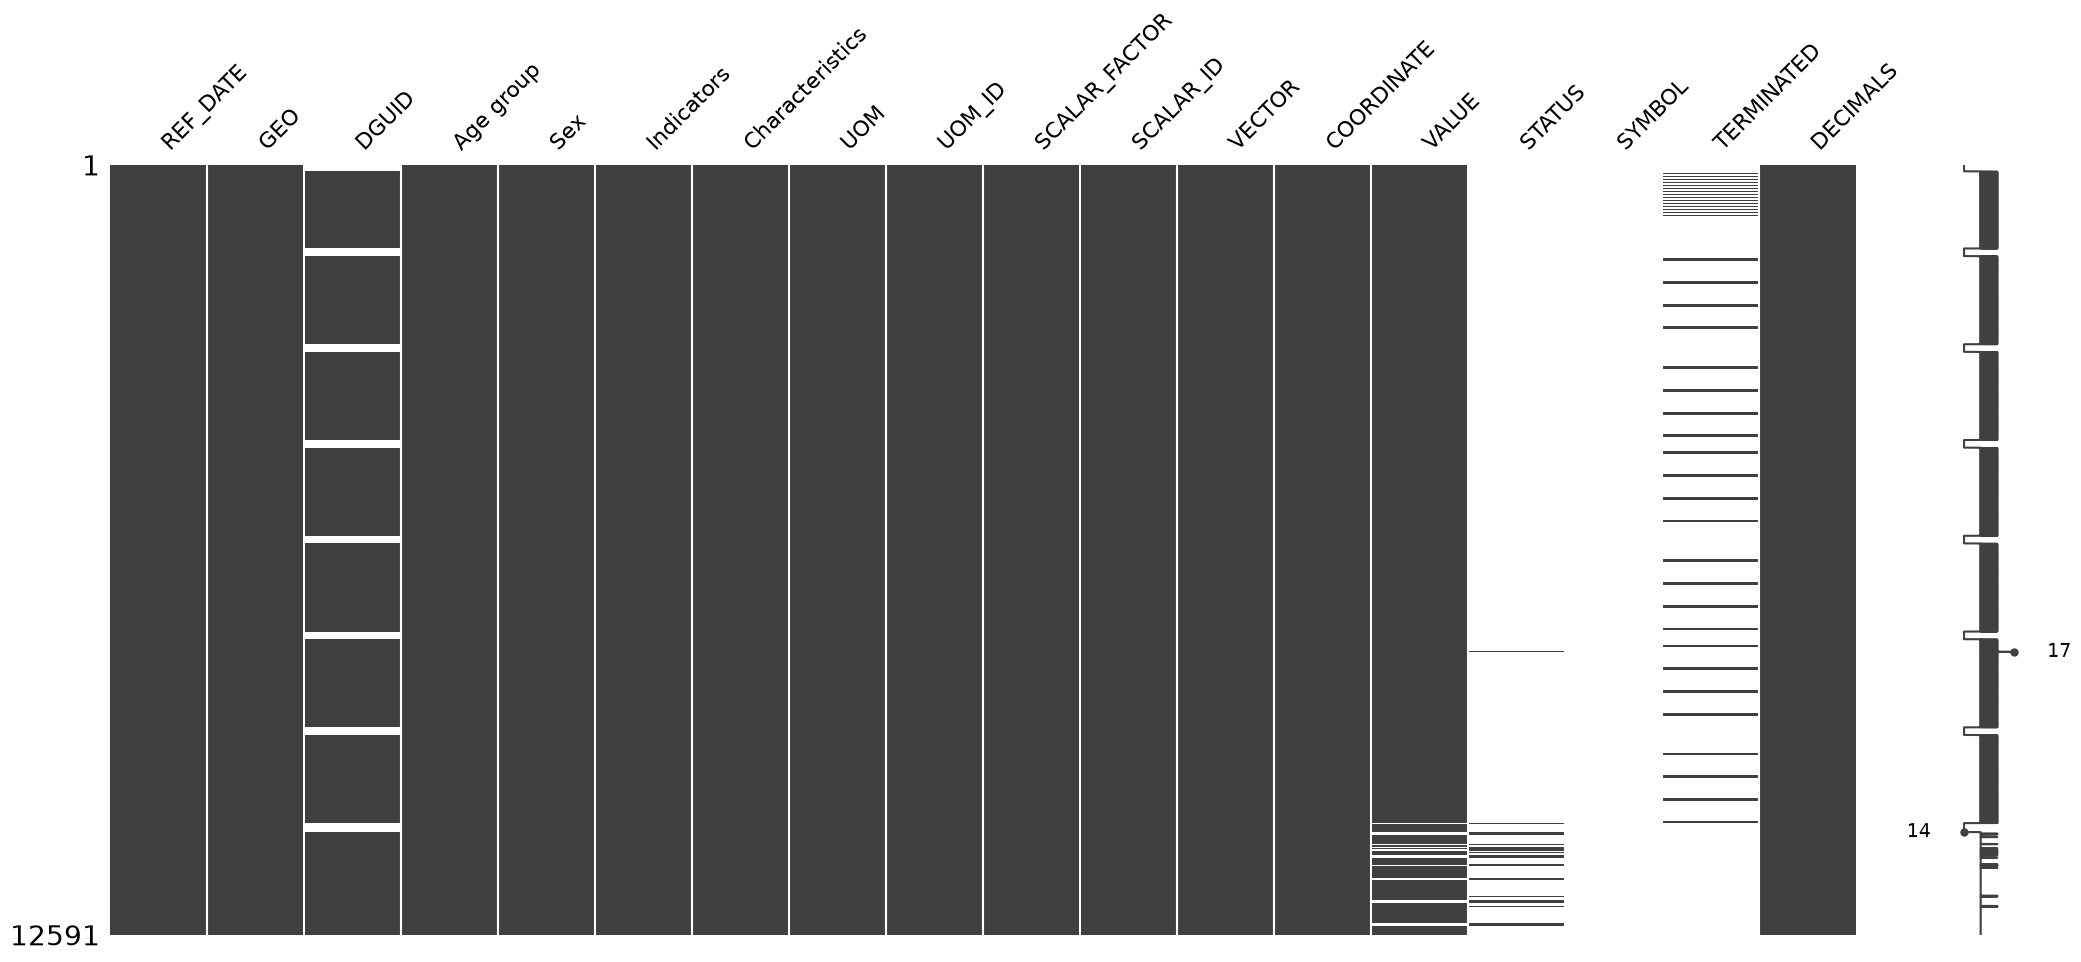

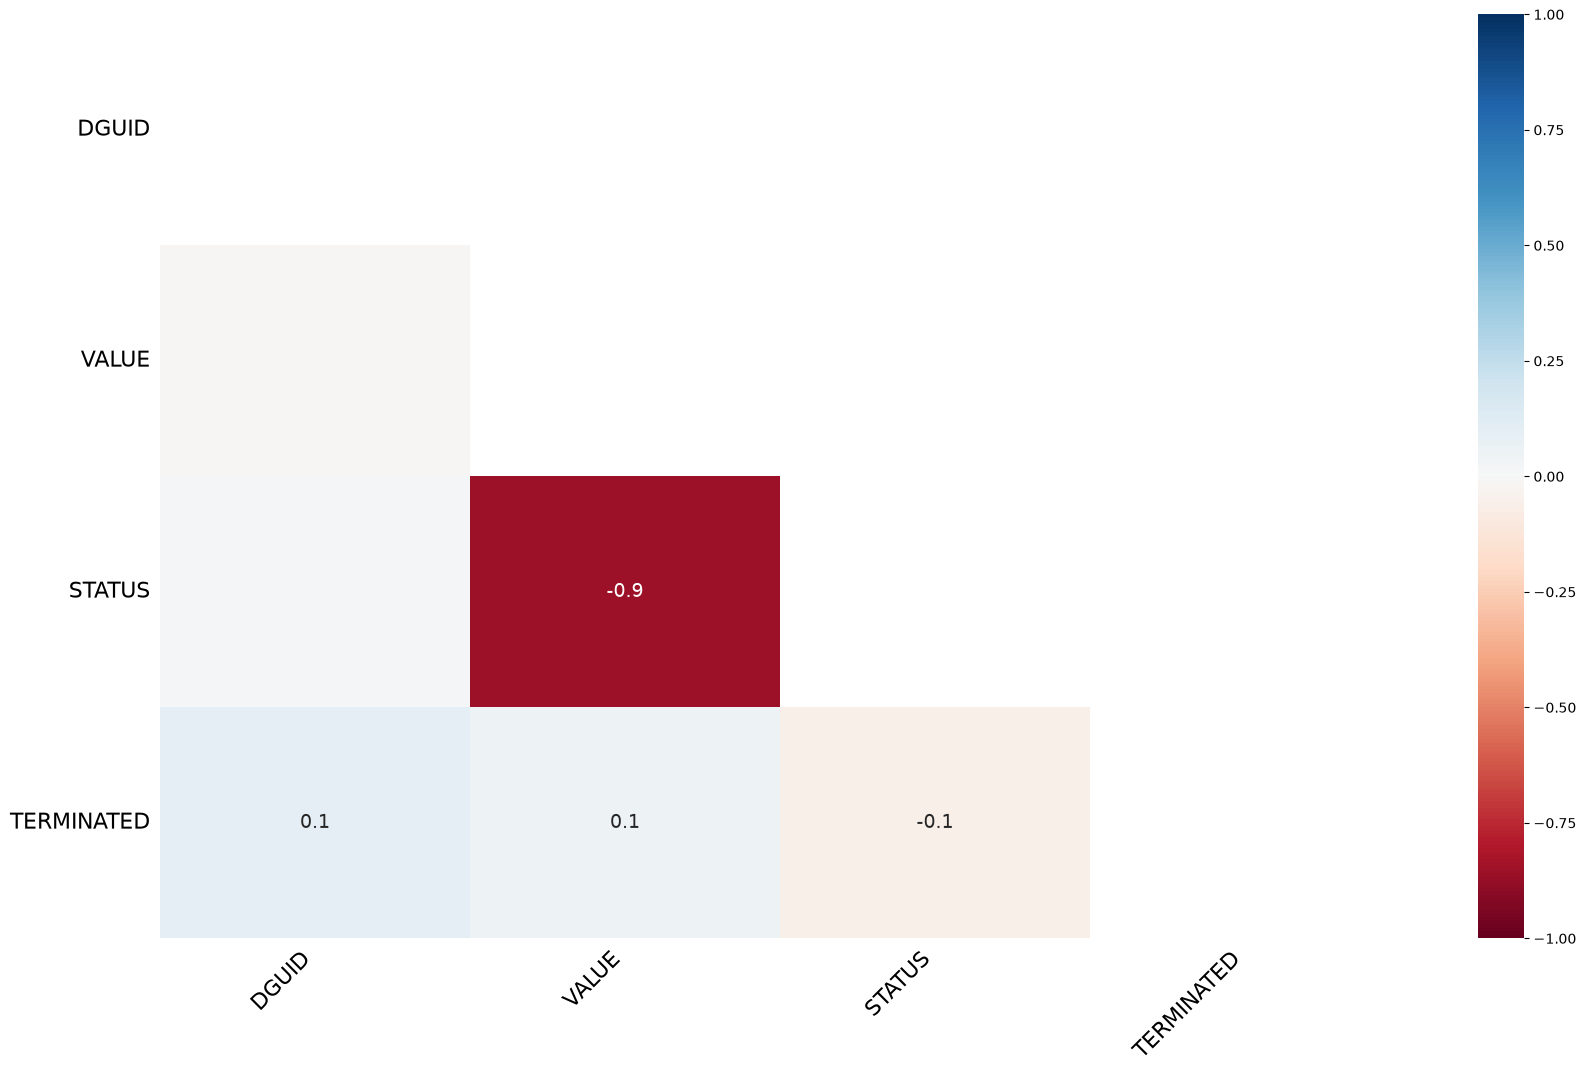

In [17]:
msno.matrix(df_hp)
plt.show()

msno.heatmap(df_hp)
plt.show()

***Analyse de la qualité des données et des valeurs manquantes :***

* **Excellente complétude des variables structurelles :** Aucune valeur manquante dans l'ensemble des colonnes principales (date, géographie, âge, sexe, caractéristiques, unités), ce qui garantit la fiabilité de la structure générale de notre jeu de données.

* **La variable cible (VALUE) :** Les 3 191 valeurs manquantes sur la colonne VALUE correspondent à des suppressions ou des masquages appliqués par StatCan (par exemple, pour des raisons de confidentialité ou de faible fiabilité statistique due à un échantillon restreint).

* **Métadonnées optionnelles :** Les volumes élevés de valeurs manquantes dans les colonnes STATUS, SYMBOL et TERMINATED sont attendus, car ces attributs ne servent qu'à annoter des situations ou des exceptions particulières.

Sur l'ensemble des colonnes structurelles (REF_DATE, GEO, Age group, Sex, Characteristics, Indicators et UOM), la complétude est totale (0 % de données manquantes), ce qui garantit l'intégrité du cadre d'analyse.

* **Pour la variable DGUID**, l'absence de valeurs concerne uniquement l'agrégat national « Canada (excluding territories) » ; il s'agit d'un manque d'information de nature non applicable (et non d'une erreur), conservé en l'état sans imputation.

* **Pour la variable cible VALUE**, les 3 191 cases vides sont entièrement expliquées par les codes officiels de la colonne STATUS (.. pour non applicable, x pour confidentialité et F pour suppression liée à une trop faible fiabilité statistique). Ce processus d'absence répond à un mécanisme MNAR (Missing Not At Random), où la donnée est masquée en fonction de sa propre valeur ou de contraintes réglementaires de censure. Conformément aux préconisations théoriques, toute imputation univariée (SimpleImputer) ou multivariée (KNNImputer, IterativeImputer) sur du MNAR introduirait un biais d'estimation critique et déformerait artificiellement les distributions. Par conséquent, aucune suppression de lignes par dropna() ni imputation par fillna() n'a été appliquée sur VALUE ; les lignes non fiables (x et F) ont été écartées lors du filtrage de qualité tout en préservant l'information binaire du drapeau STATUS.

* Enfin, **la variable SYMBOL** entièrement vide (100 % de NaN) et **la colonne TERMINATED** (présentant 90 % d'absences dues à l'arrêt d'une série spécifique par Statistique Canada) ont été traitées respectivement par suppression de la colonne inutile pour SYMBOL et par simple conservation à titre informatif pour TERMINATED.

**Les `DGUID` vides correspondent-ils tous au Canada ?**

In [18]:
df_hp.loc[df_hp["DGUID"].isna(), "GEO"].value_counts()

GEO
Canada (excluding territories)    1011
Name: count, dtype: int64

Lignes « Canada (excluding territories) » : le Canada n'a pas de code de province. Vide normal, pas une erreur.

**Les cases vides de `VALUE` sont-elles toutes expliquées par un symbole ?**

In [19]:
pd.crosstab(df_hp["STATUS"], df_hp["VALUE"].isna(), dropna=False)

VALUE,False,True
STATUS,,
..,0,231
E,110,0
F,0,81
x,0,7
NaN,12162,0


Voici la signification de chacun de ces symboles :

- **.. (deux points) :** Non disponible pour une période de référence spécifique (ou non applicable).

- **E :** À utiliser avec prudence. La donnée présente une variabilité échantillonnable élevée.

- **F :** Trop peu fiable pour être publiée. La donnée a été supprimée car la marge d'erreur est trop grande.

- **x :** Confidentiel. La valeur est masquée pour protéger l'identité des répondants en vertu de la Loi sur la statistique.

- **Validation méthodologique des valeurs manquantes (STATUS vs VALUE.isna()) :** Justification intégrale des données masquées ($3\ 191$ cas) : L'ensemble des lignes où la colonne VALUE est absente (VALUE = True) est rigoureusement expliqué par les codes de statut de Statistique Canada : l'indisponibilité pour non-applicabilité (..), la confidentialité (x) et la suppression pour faible fiabilité statistique (E et F).

- **Fiabilité des données publiées ($12\ 162$ cas) :** L'intégralité des observations renseignées (VALUE = False) ne présente aucun code de restriction (STATUS = NaN), ce qui garantit leur parfaite exploitabilité pour l'analyse analytique et cartographique.

**La colonne `TERMINATED` correspond-elle à un seul drapeau ?**

In [20]:
pd.crosstab(df_hp["Characteristics"], df_hp["TERMINATED"].fillna("(vide)"))

TERMINATED,(vide),t
Characteristics,,
"High 95% confidence interval, number of persons",1617,0
"High 95% confidence interval, percent",1617,0
"Low 95% confidence interval, number of persons",1617,0
"Low 95% confidence interval, percent",1617,0
Number of persons,1617,0
Percent,1617,0
Statistically different from previous reference period,1419,0
Statistically different from the Canada (excluding territories) rate,0,1260
Statistically different from the rest of Canada,210,0


#### Diagnostic des valeurs manquantes (indicateur « Has a regular healthcare provider », 12 591 lignes)


| Colonne | Manquantes | Interprétation | Décision |
|---|---|---|---|
| `DGUID` | 1 011 (8,0 %) | Lignes « Canada (excluding territories) » : le Canada n'a pas de code de province. Vide **normal**, pas une erreur. | Aucune action. |
| `VALUE` | 319 (2,5 %) | Cases vides expliquées par un symbole dans `STATUS` : `..` (231) + `F` (81) + `x` (7) = 319. | **Pas d'imputation.** Les cases sont conservées avec un drapeau de qualité (ticket 20). |
| `STATUS` | 12 162 (96,6 %) | Vide = **aucun symbole**, donc valeur sans réserve. Ce n'est pas un manque d'information. | Aucune action|
| `SYMBOL` | 12 591 (100 %) | Colonne entièrement vide. | Retirer de la table analytique |
| `TERMINATED` | 11 331 (90,0 %) | Rempli (`t`) sur 1 260 lignes, soit le même nombre que le drapeau « Statistically different from the Canada (excluding territories) rate ». Cette série semble arrêtée par Statistique Canada | Conservée comme information. Nous ne nous appuierons pas sur ce drapeau pour les écarts à la référence canadienne. |

Les 12 autres colonnes n'ont aucune valeur manquante.

**Constat.** Le mot « manquant » recouvre ici trois situations différentes :
1. **non applicable** (`DGUID` pour le Canada) ;
2. **supprimée ou non publiée par Statistique Canada** (`VALUE`, expliquée par `F`, `x` ou `..`) ;
3. **rien à signaler** (`STATUS` vide).

Aucune case de `VALUE` n'est vide sans symbole : il n'y a donc pas d'oubli ni d'erreur de saisie à réparer.

**Décision.** Nous n'utilisons ni `dropna()` ni `fillna()`. Supprimer les lignes retirerait tout le Canada (8 % du fichier). Imputer des moyennes inventerait des valeurs que Statistique Canada a volontairement retirées pour cause de non-disponibilité, de faible fiabilité ou de confidentialité. Cette décision applique le ticket 20 du backlog.

### Gérer les codes de qualité


Dans le dictionnaire StatCan, un STATUS vide signifie une valeur valide sans réserve. Nous allons donc remplacer les cellules vides de STATUS par 'aucun' pour leur donner du sens :

#### Nettoyage de STATUS :


In [21]:
df_hp['STATUS'] = df_hp['STATUS'].fillna('aucun')

#### Nettoyage de SYMBOL (entièrement vide, 100% NaN) :


In [22]:
if 'SYMBOL' in df_hp.columns:
    df_hp = df_hp.drop(columns=['SYMBOL'])

#### Application du filtre de qualité officiel StatCan :


- EXCLUSION : 'x' (confidentialité) et 'F' (faible fiabilité / variabilité excessive)
- CONSERVATION : 'E' (à utiliser avec précaution) et 'aucun' (valeur sûre)

In [23]:
df_filtered = df_hp[~df_hp['STATUS'].isin(['x', 'F'])].copy()

#### Affichage du rapport de contrôle du filtrage de qualité :


In [24]:
print(f"Lignes initiales (indicateur cible) : {len(df_hp)}")
print(f"Lignes après suppression des status 'F' et 'x' : {len(df_filtered)}")
print(f"Lignes exclues (non fiables ou confidentielles) : {len(df_hp) - len(df_filtered)}")
print("\nRépartition des statuts de qualité conservés :")
print(df_filtered['STATUS'].value_counts(dropna=False))

Lignes initiales (indicateur cible) : 12591
Lignes après suppression des status 'F' et 'x' : 12503
Lignes exclues (non fiables ou confidentielles) : 88

Répartition des statuts de qualité conservés :
STATUS
aucun    12162
..         231
E          110
Name: count, dtype: int64


### Typer les variables et passer en format long


Les colonnes inutiles identifiées dans notre Spike vont être supprimées dans cette étape :

#### Suppression des colonnes inutiles :


In [25]:
cols_inutiles = [
    'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID',
    'VECTOR', 'COORDINATE', 'DECIMALS'
]
df_filtered = df_filtered.drop(columns=[c for c in cols_inutiles if c in df_filtered.columns])

#### Séparation des mesures réelles et drapeaux statistiques :



Séparation des mesures réelles d'accès aux soins vs les drapeaux d'écart statistique (Pour ne pas mélanger des pourcentages avec des codes 0, 1, -1 lors des calculs) :

In [26]:
is_flag = df_filtered['Characteristics'].str.startswith('Statistically different')
df_measures = df_filtered[~is_flag].copy()
df_flags = df_filtered[is_flag].copy()

#### Conversion du champ VALUE en numérique continu :


In [27]:
df_measures['VALUE'] = pd.to_numeric(df_measures['VALUE'], errors='coerce')

#### Transformation du jeu de données du format long vers un format wide (analytique) :


In [28]:
# Dictionnaire de reformatage des noms de caractéristiques (Pivotement)
char_map = {
    'Number of persons': 'val_number',
    'Low 95% confidence interval, number of persons': 'ci_low_number',
    'High 95% confidence interval, number of persons': 'ci_high_number',
    'Percent': 'val_percent',
    'Low 95% confidence interval, percent': 'ci_low_percent',
    'High 95% confidence interval, percent': 'ci_high_percent'
}
df_measures['char_clean'] = df_measures['Characteristics'].map(char_map)

In [29]:
# Pivotement : Obtenir une ligne unique par cellule (REF_DATE x GEO x DGUID x Age group x Sex)
index_cols = ['REF_DATE', 'GEO', 'Age group', 'Sex']

In [30]:
df_pivoted = df_measures.pivot_table(
    index=index_cols,
    columns='char_clean',
    values='VALUE',
    aggfunc='first',
    dropna=False
).reset_index()

In [31]:
# Récupération du statut de qualité principal (associé à la mesure 'val_percent') :
df_status = df_measures[df_measures['char_clean'] == 'val_percent'][index_cols + ['STATUS']]

In [32]:
# Fusion finale :
df_analytic = pd.merge(df_pivoted, df_status, on=index_cols, how='left')

In [33]:
# RAPPORT DU PIVOTEMENT ET TYPAGE (TICKETS 21)
print("--- SUCCÈS DU PIVOTEMENT ET DUB TYPAGE (TICKET 21) ---")
print(f"Dimensions de la table analytique pivotée : {df_analytic.shape}")
print(f"Colonnes générées dans df_analytic : {df_analytic.columns.tolist()}")

--- SUCCÈS DU PIVOTEMENT ET DUB TYPAGE (TICKET 21) ---
Dimensions de la table analytique pivotée : (1848, 11)
Colonnes générées dans df_analytic : ['REF_DATE', 'GEO', 'Age group', 'Sex', 'ci_high_number', 'ci_high_percent', 'ci_low_number', 'ci_low_percent', 'val_number', 'val_percent', 'STATUS']


In [34]:
df_analytic.sample()

,REF_DATE,GEO,Age group,Sex,ci_high_number,ci_high_percent,ci_low_number,ci_low_percent,val_number,val_percent,STATUS
1027,2019,New Brunswick,"Total, 18 years and over",Females,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Créer les variables de période


Cette étape ajoute à la table analytique les variables temporelles requises pour l'analyse des tendances, la prise en compte de la pandémie de COVID-19 et la gestion de la rupture méthodologique de Statistique Canada en 2022.

#### Découpage souhaité :


* Avant 2020 (Pre-COVID) : Période de référence historique (2015 à 2019).

* 2020-2021 (Pandémie) : Période de perturbations majeures du système de santé.

* 2022 et après (Post-COVID) : Période de reprise / situation récente.

#### Rupture méthodologique :


* Statistique Canada a ajusté la formulation de la question de l'ESCC en 2022.

* La variable binaire is_post_2022_methodology (ou PERIOD_SURVEY) permet d'isoler cette rupture dans les modèles et visualisations.

In [35]:
# Variable catégorielle pour la segmentation par période COVID :
df_analytic['PERIOD_COVID'] = np.where(
    df_analytic['REF_DATE'] < 2020, 'Avant 2020 (Pre-COVID)',
    np.where(
        df_analytic['REF_DATE'] <= 2021, '2020-2021 (Pandémie)',
        '2022 et après (Post-COVID)'
    )
)

In [36]:
df_analytic['PERIOD_COVID'].value_counts()

PERIOD_COVID
Avant 2020 (Pre-COVID)        1155
2020-2021 (Pandémie)           462
2022 et après (Post-COVID)     231
Name: count, dtype: int64

In [37]:
# Variable binaire de rupture méthodologique (StatCan 2022) :
df_analytic['is_post_2022_methodology'] = (df_analytic['REF_DATE'] >= 2022).astype(int)
df_analytic['is_post_2022_methodology'].value_counts()

is_post_2022_methodology
0    1617
1     231
Name: count, dtype: int64

In [38]:
# Libellé clair de la période d'enquête
df_analytic['PERIOD_SURVEY'] = np.where(
    df_analytic['REF_DATE'] < 2022,
    'Ancienne méthodologie (2015-2021)',
    'Nouvelle méthodologie (2022+)'
)
df_analytic.sample()

,REF_DATE,GEO,Age group,Sex,ci_high_number,ci_high_percent,ci_low_number,ci_low_percent,val_number,val_percent,STATUS,PERIOD_COVID,is_post_2022_methodology,PERIOD_SURVEY
385,2016,Ontario,35 to 49 years,Females,1306300.0,95.5,1240000.0,91.6,1276900.0,93.8,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)


#### Vérification de la pertinence des variables de période :


In [39]:
pd.crosstab(df_analytic['REF_DATE'], df_analytic['PERIOD_SURVEY'])

PERIOD_SURVEY,Ancienne méthodologie (2015-2021),Nouvelle méthodologie (2022+)
REF_DATE,,
2015,231,0
2016,231,0
2017,231,0
2018,231,0
2019,231,0
2020,231,0
2021,231,0
2022,0,231


### Nettoyage global : Contrôler la cohérence des données


#### Vérification des bornes de pourcentage (val_percent) :


In [40]:
# Contrôle des plages de valeurs (Pourcentages entre 0 et 100)
out_of_bounds_pct = df_analytic[
    (df_analytic['val_percent'] < 0) | (df_analytic['val_percent'] > 100)
]
print(f"Pourcentages hors limites [0, 100] : {len(out_of_bounds_pct)}")

Pourcentages hors limites [0, 100] : 0


#### Cohérence des intervalles de confiance (IC à 95 %) :


In [41]:
# On ignore les lignes où les IC sont NaN (données masquées/exclues)
valid_ic = df_analytic.dropna(subset=['ci_low_percent', 'val_percent', 'ci_high_percent'])

inconsistent_ic_low = valid_ic[valid_ic['ci_low_percent'] > valid_ic['val_percent']]
inconsistent_ic_high = valid_ic[valid_ic['val_percent'] > valid_ic['ci_high_percent']]

print(f"Anomalies IC Inférieur (ci_low > val) : {len(inconsistent_ic_low)}")
print(f"Anomalies IC Supérieur (val > ci_high) : {len(inconsistent_ic_high)}")

Anomalies IC Inférieur (ci_low > val) : 0
Anomalies IC Supérieur (val > ci_high) : 0


#### Cohérence des effectifs (val_number) :


In [42]:
negative_counts = df_analytic[df_analytic['val_number'] < 0]
print(f"Effectifs de personnes négatifs : {len(negative_counts)}")

Effectifs de personnes négatifs : 0


#### Intégrité de l'index et absence de doublons :


In [43]:
# Contrôle des doublons sur la clé primaire
primary_key = ['REF_DATE', 'GEO', 'Age group', 'Sex']
nb_duplicates = df_analytic.duplicated(subset=primary_key).sum()
print(f"Doublons sur la clé primaire {primary_key} : {nb_duplicates}")
assert nb_duplicates == 0, "ERREUR : Des doublons existent sur la clé primaire !"

Doublons sur la clé primaire ['REF_DATE', 'GEO', 'Age group', 'Sex'] : 0


Aucune anomalie, nous allons donc continuer notre prétraitement.

### Livrable : produire le rapport d'audit de qualité et la table analytique nettoyée


In [44]:
df_analytic.to_csv('../data/table_analytique_nettoyee.csv', index=False, encoding='utf-8')

## 1.2. Suivre l'évolution nationale de l'accès


### Calculer la série nationale du taux d'accès et de non-couverture

In [45]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/table_analytique_nettoyee.csv')

df.head()


,REF_DATE,GEO,Age group,Sex,ci_high_number,ci_high_percent,ci_low_number,ci_low_percent,val_number,val_percent,STATUS,PERIOD_COVID,is_post_2022_methodology,PERIOD_SURVEY
0,2015,Alberta,12 to 17 years,Both sexes,226000.0,85.8,200500.0,76.6,213300.0,81.2,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)
1,2015,Alberta,12 to 17 years,Females,110800.0,87.6,91900.0,73.2,101400.0,80.4,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)
2,2015,Alberta,12 to 17 years,Males,120200.0,87.7,103600.0,76.1,111900.0,81.9,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)
3,2015,Alberta,18 to 34 years,Both sexes,770200.0,71.3,697700.0,64.6,733900.0,68.0,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)
4,2015,Alberta,18 to 34 years,Females,440900.0,83.5,398300.0,75.4,419600.0,79.5,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)


In [46]:

# Sélectionner le Canada, les deux sexes et les 12 ans et plus
df_national = df[
    (df["GEO"] == "Canada (excluding territories)") &
    (df["Age group"] == "Total, 12 years and over") &
    (df["Sex"] == "Both sexes")
].copy()

# Calculer le taux de non-couverture
df_national["taux_non_couverture"] = 100 - df_national["val_percent"]

# Afficher la série chronologique
resultat_national = df_national[
    ["REF_DATE", "val_percent", "taux_non_couverture"]
].sort_values("REF_DATE")

display(resultat_national)


,REF_DATE,val_percent,taux_non_couverture
57,2015,83.2,16.8
288,2016,84.2,15.8
519,2017,84.7,15.3
750,2018,85.3,14.7
981,2019,85.5,14.5
1212,2020,85.8,14.2
1443,2021,85.5,14.5
1674,2022,86.0,14.0


Interprétation : le taux publié passe de 83,2 % en 2015 à 86,0 % en 2022, soit une augmentation de 2,8 points de pourcentage. Il faut toutefois tenir compte du changement méthodologique de 2022 avant d'interpréter cette évolution.

### Estimer la tendance 2015-2019 (H1)

In [47]:

# Sélectionner les années 2015 à 2019
periode = resultat_national[
    resultat_national["REF_DATE"].between(2015, 2019)
]

# Récupérer les taux de début et de fin
taux_2015 = periode.loc[
    periode["REF_DATE"] == 2015, "val_percent"
].iloc[0]

taux_2019 = periode.loc[
    periode["REF_DATE"] == 2019, "val_percent"
].iloc[0]

# Calculer la variation en points de pourcentage
variation = taux_2019 - taux_2015

# Calculer la variation annuelle moyenne
variation_annuelle = variation / (2019 - 2015)

print(f"Taux en 2015 : {taux_2015:.1f} %")
print(f"Taux en 2019 : {taux_2019:.1f} %")
print(f"Variation totale : {variation:+.1f} points")
print(f"Variation annuelle moyenne : {variation_annuelle:+.3f} point/an")


Taux en 2015 : 83.2 %
Taux en 2019 : 85.5 %
Variation totale : +2.3 points
Variation annuelle moyenne : +0.575 point/an


Entre 2015 et 2019, le taux national d'accès à un fournisseur habituel de soins de santé a augmenté de 2,3 points de pourcentage, soit une progression annuelle moyenne de 0,575 point. Cette évolution est descriptive et ne suffit pas, à elle seule, à confirmer statistiquement l'hypothèse H1.

### Estimer le nombre de personnes sans fournisseur

In [48]:

# Estimation du nombre de personnes sans fournisseur habituel

# Estimer la population totale à partir des données publiées
df_national["population_estimee"] = (
    df_national["val_number"] /
    (df_national["val_percent"] / 100)
)

# Calculer le nombre estimé de personnes sans fournisseur
df_national["sans_fournisseur_estime"] = (
    df_national["population_estimee"] -
    df_national["val_number"]
)

# Afficher les résultats arrondis au millier
resultat_sans_fournisseur = df_national[
    ["REF_DATE", "sans_fournisseur_estime"]
].sort_values("REF_DATE").copy()

resultat_sans_fournisseur["sans_fournisseur_estime"] = (
    resultat_sans_fournisseur["sans_fournisseur_estime"]
    .round(-3)
    .astype(int)
)

display(resultat_sans_fournisseur)


,REF_DATE,sans_fournisseur_estime
57,2015,5010000
288,2016,4784000
519,2017,4702000
750,2018,4586000
981,2019,4581000
1212,2020,4555000
1443,2021,4693000
1674,2022,4604000


En 2022, environ 4,6 millions de personnes de 12 ans et plus au Canada (sauf les territoires) étaient estimées sans fournisseur habituel de soins de santé, soit 14 % de la population concernée. Cette estimation repose sur les données publiées par Statistique Canada.

### Spike : Évaluation de la comparabilité de la rupture de série 2022 de Statistique Canada


**Objectif du Spike**

Vérifier la comparabilité des taux d'accès à un fournisseur habituel de soins de santé entre 2015 et 2022.

**Constat**

Selon la note 8 du tableau 13-10-0096-16 de Statistique Canada, la question utilisée pour mesurer cet indicateur a été modifiée en 2022.

Le taux national publié passe de 85,5 % en 2021 à 86,0 % en 2022, soit une augmentation de 0,5 point de pourcentage.

Cependant, cette variation ne peut pas être interprétée uniquement comme une amélioration réelle de l'accès aux soins, car le changement de question peut influencer les résultats.

**Décision pour notre analyse**

- Conserver les données de 2015 à 2022.
- Signaler le changement méthodologique de 2022.
- Interpréter avec prudence les comparaisons entre 2022 et les années précédentes.
- Ne pas attribuer la variation observée uniquement à une évolution réelle de l'accès aux soins.

**Conclusion**

Les données de 2022 peuvent être présentées dans notre analyse descriptive, mais leur comparaison avec les années précédentes nécessite une réserve méthodologique.

**Source**

Statistique Canada, tableau 13-10-0096-16, note 8.

https://www150.statcan.gc.ca/t1/tbl1/fr/tv.action?pid=1310009616


### Livrable : créer le graphique de tendance nationale annoté

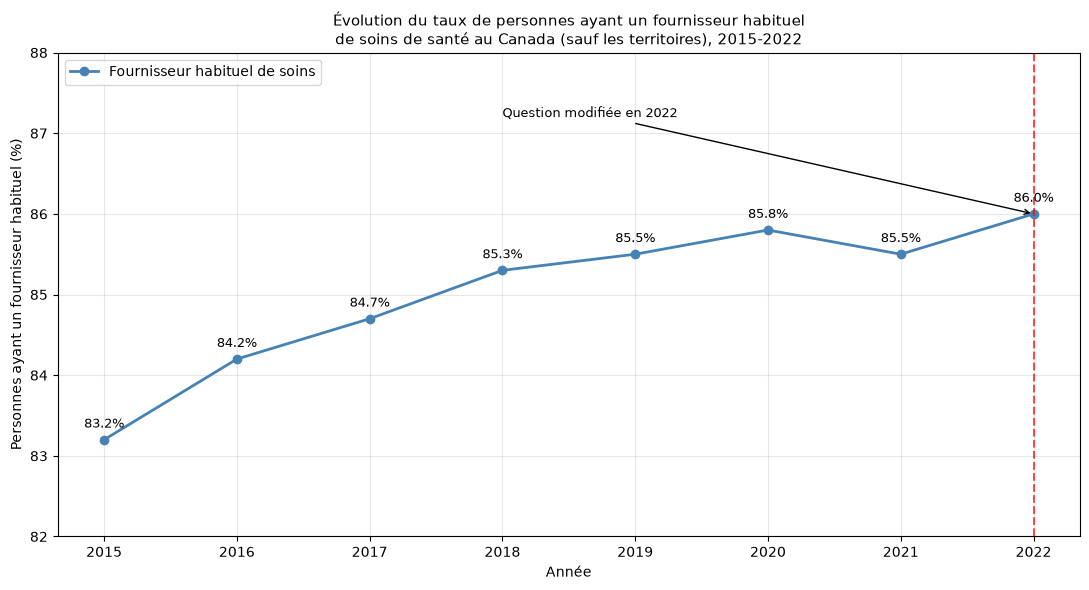

In [49]:

# Source : Statistique Canada, tableau 13-10-0096-16

import matplotlib.pyplot as plt

# Préparer les données nationales
serie = resultat_national.sort_values("REF_DATE")

# Créer le graphique
plt.figure(figsize=(11, 6))

plt.plot(
    serie["REF_DATE"],
    serie["val_percent"],
    marker="o",
    linewidth=2,
    color="steelblue",
    label="Fournisseur habituel de soins"
)

# Afficher les pourcentages sur chaque point
for annee, taux in zip(
    serie["REF_DATE"], serie["val_percent"]
):
    plt.text(
        annee,
        taux + 0.15,
        f"{taux:.1f}%",
        ha="center",
        fontsize=9
    )

# Signaler le changement méthodologique de 2022
plt.axvline(
    x=2022,
    color="red",
    linestyle="--",
    alpha=0.7
)

plt.annotate(
    "Question modifiée en 2022",
    xy=(2022, 86),
    xytext=(2018, 87.2),
    fontsize=9,
    arrowprops=dict(
        arrowstyle="->",
        color="black"
    )
)

# Titre précis selon l'indicateur officiel
plt.title(
    "Évolution du taux de personnes ayant un fournisseur habituel\n"
    "de soins de santé au Canada (sauf les territoires), 2015-2022",
    fontsize=11
)

plt.xlabel("Année")
plt.ylabel("Personnes ayant un fournisseur habituel (%)")

plt.xticks(serie["REF_DATE"])
plt.ylim(82, 88)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# Afficher le graphique
plt.show()


Entre 2015 et 2021, le taux national de personnes ayant un fournisseur habituel de soins de santé est passé de 83,2 % à 85,5 %, avec quelques fluctuations. En 2022, le taux publié atteint 86,0 %. Toutefois, Statistique Canada indique que la question utilisée pour mesurer cet indicateur a été modifiée en 2022. Les comparaisons avec les années précédentes doivent donc être interprétées avec prudence.

## 1.3. Comparer les provinces


### Normaliser la géographie

#Comparaison des provinces et trajectoires régionales

**Entrée** : `table_analytique_nettoyee.csv` (notebook 1)

**Epic** : Portrait de l'accès dans le temps et par région (Sprint 2)


## US-05 : Comparer les provinces


### Normaliser la géographie


In [50]:
import os
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR=os.path.join('..','data')
OUT_DIR=os.path.join('..','figures')
os.makedirs(OUT_DIR,exist_ok=True)

df=pd.read_csv(os.path.join(DATA_DIR,'table_analytique_nettoyee.csv'))
REF_AGE,REF_SEX='Total, 12 years and over','Both sexes'
prov=df[(df['GEO']!='Canada (excluding territories)')&(df['Age group']==REF_AGE)&(df['Sex']==REF_SEX)].copy()
prov[['GEO']].drop_duplicates().sort_values('GEO')


,GEO
15,Alberta
36,British Columbia
78,Manitoba
99,New Brunswick
120,Newfoundland and Labrador
141,Nova Scotia
162,Ontario
183,Prince Edward Island
204,Quebec
225,Saskatchewan


### Calculer l'écart de chaque région à la moyenne nationale (H2)


In [51]:
nat=df[(df['GEO']=='Canada (excluding territories)')&(df['Age group']==REF_AGE)&(df['Sex']==REF_SEX)][['REF_DATE','val_percent']].rename(columns={'val_percent':'nat'})
prov=prov.merge(nat,on='REF_DATE')
prov['ecart_pts']=prov['val_percent']-prov['nat']
prov[['GEO','REF_DATE','val_percent','ecart_pts']].head()


,GEO,REF_DATE,val_percent,ecart_pts
0,Alberta,2015,80.5,-2.7
1,British Columbia,2015,83.8,0.6
2,Manitoba,2015,81.8,-1.4
3,New Brunswick,2015,90.8,7.6
4,Newfoundland and Labrador,2015,88.1,4.9


In [52]:
#Ce tableau mesure l'écart de chaque province par rapport à la moyenne canadienne en points de pourcentage, montrant par exemple qu'en 2015 le Nouveau-Brunswick dépassait nettement la moyenne (+7,6 points) tandis que l'Alberta se situait en dessous (-2,7 points).

### Livrable : classement provincial (dernière année)


In [53]:
last=prov['REF_DATE'].max()
rang=prov[prov['REF_DATE']==last][['GEO','val_percent','ecart_pts']].sort_values('val_percent',ascending=False)
rang


,GEO,val_percent,ecart_pts
76,Ontario,90.2,4.2
70,Alberta,89.3,3.3
73,New Brunswick,89.3,3.3
72,Manitoba,89.0,3.0
75,Nova Scotia,85.2,-0.8
79,Saskatchewan,84.9,-1.1
71,British Columbia,83.4,-2.6
74,Newfoundland and Labrador,81.9,-4.1
78,Quebec,78.7,-7.3
77,Prince Edward Island,75.9,-10.1


Ce classement de la dernière année place l'Ontario en tête avec le meilleur taux d'accès (90,2 %, soit +4,2 points au-dessus de la moyenne), tandis que le Québec (78,7 %) et l'Île-du-Prince-Édouard (75,9 %) ferment la marche avec les plus forts retards.

### Graphique : classement provincial


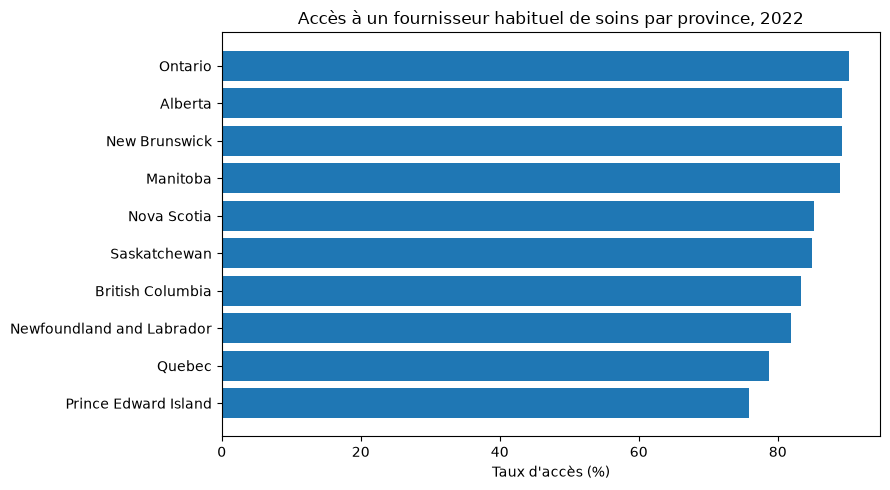

In [54]:
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(rang['GEO'],rang['val_percent'])
ax.invert_yaxis()
ax.set_xlabel("Taux d'accès (%)")
ax.set_title(f"Accès à un fournisseur habituel de soins par province, {last}")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR,'classement_provincial.png'),dpi=200,bbox_inches='tight')
plt.show()


Constats:

Ce graphique illustre visuellement le classement provincial de 2022, mettant en évidence un groupe de tête autour de 90 % (mené par l'Ontario, l'Alberta, le Nouveau-Brunswick et le Manitoba) et un décrochage net en bas de classement pour le Québec et l'Île-du-Prince-Édouard.

L'année 2022 est séparée en raison d'une rupture méthodologique dans l'enquête (ESCC), ce qui impose d'interpréter avec prudence toute comparaison directe entre 2022 et les années précédentes.

## Test de significativité des écarts régionaux (z-test, seuil 5 points)

**Objectif** : Tester H₀ : l'écart provincial vs national est < 5 points (au lieu de ≠ 0).
Cela répond directement à la question métier : les différences d'accès sont-elles cliniquement/socialement significatives ?

**Méthode** : Pour chaque province sur la dernière année (2022) :
- SE = (CI_high - CI_low) / (2 × 1.96)  (intervalle de confiance 95%)
- SE_diff = √(SE_province² + SE_national²)
- z_seuil = (|écart| - 5) / SE_diff  (teste directement le seuil de 5 points)
- p = 1 - Φ(z_seuil) si z_seuil > 0, sinon p = 1  (test unilatéral H₁ : |écart| > 5)

**Limite** : La province fait partie du national → les deux estimations ne sont pas totalement indépendantes.
Le test est donc légèrement conservateur (p-values légèrement surestimées).

In [55]:
from scipy import stats
import numpy as np

# Dernière année disponible
last = df['REF_DATE'].max()

# Données province + national pour la dernière année, avec IC
prov_last = df[(df['REF_DATE']==last) & (df['GEO']!='Canada (excluding territories)') & (df['Age group']==REF_AGE) & (df['Sex']==REF_SEX)]
nat_last = df[(df['REF_DATE']==last) & (df['GEO']=='Canada (excluding territories)') & (df['Age group']==REF_AGE) & (df['Sex']==REF_SEX)]

# Calculer SE depuis IC 95%
prov_last = prov_last.copy()
prov_last['SE'] = (prov_last['ci_high_percent'] - prov_last['ci_low_percent']) / (2 * 1.96)
nat_se = (nat_last['ci_high_percent'].values[0] - nat_last['ci_low_percent'].values[0]) / (2 * 1.96)
nat_val = nat_last['val_percent'].values[0]

# Test z pour chaque province
results = []
for _, row in prov_last.iterrows():
    ecart = row['val_percent'] - nat_val
    se_diff = np.sqrt(row['SE']**2 + nat_se**2)
    z_seuil = (abs(ecart) - 5) / se_diff
    # Test unilatéral H₁ : |écart| > 5 points
    p = 1 - stats.norm.cdf(z_seuil) if z_seuil > 0 else 1.0
    results.append({
        'Province': row['GEO'],
        'Taux_province': round(row['val_percent'], 1),
        'Taux_national': round(nat_val, 1),
        'Ecart_pts': round(ecart, 1),
        'SE_province': round(row['SE'], 3),
        'SE_national': round(nat_se, 3),
        'SE_diff': round(se_diff, 3),
        'z_seuil': round(z_seuil, 3),
        'p_value': round(p, 4),
        'Significatif_5pts (p<0.05)': p < 0.05
    })

res_df = pd.DataFrame(results).sort_values('Ecart_pts', ascending=False)
res_df


,Province,Taux_province,Taux_national,Ecart_pts,SE_province,SE_national,SE_diff,z_seuil,p_value,Significatif_5pts (p<0.05)
6,Ontario,90.2,86.0,4.2,0.408,0.23,0.468,-1.708,1.0000,False
0,Alberta,89.3,86.0,3.3,0.561,0.23,0.606,-2.804,1.0000,False
3,New Brunswick,89.3,86.0,3.3,0.944,0.23,0.971,-1.750,1.0000,False
2,Manitoba,89.0,86.0,3.0,0.867,0.23,0.897,-2.229,1.0000,False
5,Nova Scotia,85.2,86.0,-0.8,1.046,0.23,1.071,-3.922,1.0000,False
9,Saskatchewan,84.9,86.0,-1.1,1.224,0.23,1.246,-3.130,1.0000,False
1,British Columbia,83.4,86.0,-2.6,0.663,0.23,0.702,-3.419,1.0000,False
4,Newfoundland and Labrador,81.9,86.0,-4.1,1.429,0.23,1.447,-0.622,1.0000,False
8,Quebec,78.7,86.0,-7.3,0.587,0.23,0.630,3.650,0.0001,True
7,Prince Edward Island,75.9,86.0,-10.1,2.857,0.23,2.866,1.779,0.0376,True


## Interprétation des résultats du z-test (seuil 5 points)
En 2022, le test de significativité au seuil métier de 5 points révèle que seuls le Québec et l'Île-du-Prince-Édouard présentent un déficit d'accès statistiquement et socialement significatif par rapport à la moyenne nationale.

À l'opposé, aucune des provinces en tête de classement (Ontario, Alberta, Nouveau-Brunswick et Manitoba) ne dépasse significativement ce seuil au-dessus de la moyenne canadienne.

Les quatre autres provinces situées sous la moyenne (Nouvelle-Écosse, Saskatchewan, Colombie-Britannique et Terre-Neuve-et-Labrador) affichent également des écarts jugés non significatifs.

Enfin, comme chaque province est incluse dans la moyenne nationale, ce test reste légèrement conservateur, ce qui renforce la fiabilité du constat pour le Québec et l'Île-du-Prince-Édouard tout en invitant à la prudence pour les provinces proches du seuil.

## US-06 : Identifier les régions qui progressent ou reculent


### 1. Construire l'indice de variation par région

In [57]:
# Créer une vue pivotée de prov (Provinces en lignes, Années en colonnes)
prov_pivot = prov.pivot_table(index='GEO', columns='REF_DATE', values='val_percent')

# Variation en points depuis 2015 (année de référence)
var = (prov_pivot[2022] - prov_pivot[2015]).sort_values()
print(var.round(1))

GEO
Prince Edward Island        -12.8
Newfoundland and Labrador    -6.2
Nova Scotia                  -3.5
New Brunswick                -1.5
British Columbia             -0.4
Ontario                       0.6
Saskatchewan                  4.0
Quebec                        6.5
Manitoba                      7.2
Alberta                       8.8
dtype: float64


La variation 2015→2022 résume la trajectoire de chaque région ; un signe positif indique une amélioration de l'accès.

### 2. Classer les trajectoires

In [58]:
seuil = 2  # points

def categorie(v):
    return 'Amélioration' if v > seuil else ('Détérioration' if v < -seuil else 'Stable')

traj = var.to_frame('variation').assign(groupe=lambda d: d['variation'].apply(categorie))
print(traj.round(1))

                           variation         groupe
GEO                                                
Prince Edward Island           -12.8  Détérioration
Newfoundland and Labrador       -6.2  Détérioration
Nova Scotia                     -3.5  Détérioration
New Brunswick                   -1.5         Stable
British Columbia                -0.4         Stable
Ontario                          0.6         Stable
Saskatchewan                     4.0   Amélioration
Quebec                           6.5   Amélioration
Manitoba                         7.2   Amélioration
Alberta                          8.8   Amélioration


Chaque province est classée en Amélioration / Stable / Détérioration selon un seuil de ±2 points. 
Résultat : **détérioration** à l'Î.-P.-É., à Terre-Neuve-et-Labrador et en Nouvelle-Écosse ; **amélioration** en Saskatchewan, au Québec, au Manitoba et en Alberta.

3. Valider les groupes avec le sens métier

In [59]:
print(traj['groupe'].value_counts())

groupe
Amélioration     4
Détérioration    3
Stable           3
Name: count, dtype: int64


**Validation :** les groupes doivent rester cohérents avec les écarts régionaux (1.3). La rupture de série 2022 peut décaler certaines trajectoires, d'où la prudence d'interprétation.

### 4. Livrable : créer le graphique en petits multiples des trajectoires régionales

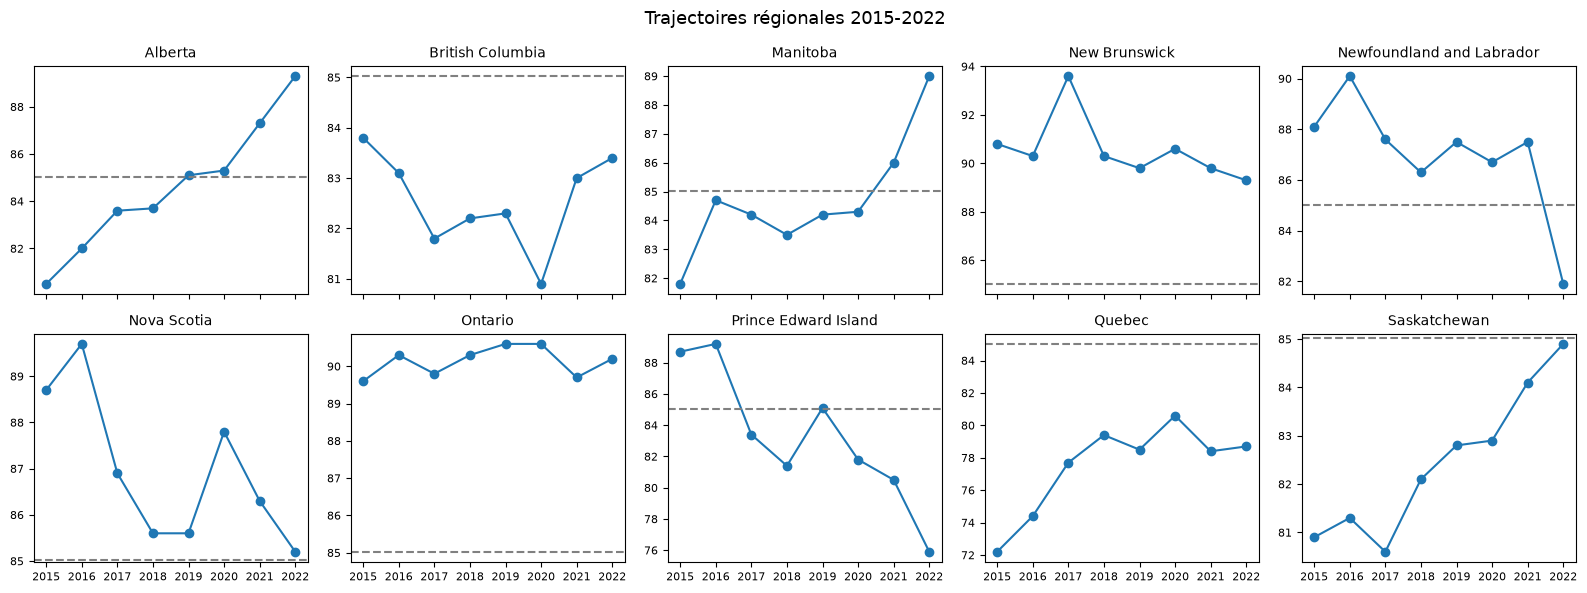

In [61]:
# Pivoter prov par ordre alphabétique des provinces
prov_pivot = prov.pivot_table(index='GEO', columns='REF_DATE', values='val_percent').sort_index()

# Moyenne nationale globale sur la période (ligne horizontale à ~85.0 %)
moyenne_nat = nat['nat'].mean()

fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharex=True, sharey=False)

for ax, province in zip(axes.flat, prov_pivot.index):
    ax.plot(prov_pivot.columns, prov_pivot.loc[province], 'o-')
    ax.axhline(moyenne_nat, color='grey', linestyle='--')
    ax.set_title(province, fontsize=10)
    ax.set_xticks(prov_pivot.columns)
    ax.tick_params(axis='both', labelsize=8)

fig.suptitle("Trajectoires régionales 2015-2022", fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'trajectoires_regionales.png'), dpi=200, bbox_inches='tight')
plt.show()

**Alberta :** Progression continue passant de 80,5 % à 89,3 %, dépassant la moyenne nationale dès 2019.   
**British Columbia :** Taux constamment sous la moyenne nationale avec un creux en 2020 (80,9 %) suivi d'un léger rebond.   
**Manitoba :** Forte hausse en fin de période permettant de franchir la moyenne nationale dès 2021 pour atteindre 89,0 %.   
**New Brunswick :** Maintien élevé nettement au-dessus de la référence (89,3 % à 93,6 %) malgré une légère baisse après 2017.   
**Newfoundland and Labrador :** Taux supérieur à la moyenne jusqu'en 2021 suivi d'une chute brutale à 81,9 % en 2022.   
**Nova Scotia :** Baisse globale (89,7 % en 2016 à 85,2 % en 2022) ramenant la province juste au niveau de la moyenne.   
**Ontario :** Performance très stable et élevée autour de 90 % sur toute la période, loin au-dessus de la référence.   
**Prince Edward Island :** Chute marquée de 89,2 % (2016) à 75,9 % (2022), passant largement sous la moyenne nationale.   
**Quebec :** Progression notable depuis 2015 (+6,5 pts) mais taux demeurant toujours très en deçà de la référence.   
**Saskatchewan :** Hausse régulière depuis 2017 (80,6 % à 84,9 %) venant presque rejoindre la moyenne nationale en 2022.

### Construire l'indice de variation par région


### Spike : Évaluation des seuils de suppression et de la fiabilité statistique des petites provinces

### Calculer l'écart de chaque région à la moyenne nationale (H2)

### Tester la significativité des écarts et le seuil de 5 points

### Livrable : créer le classement provincial et la carte choroplèthe des écarts

## 1.4. Identifier les régions qui progressent ou reculent


### Construire l'indice de variation par région

### Classer les trajectoires

### Valider les groupes avec le sens métier

### Livrable : créer le graphique en petits multiples des trajectoires régionales

# 2. Comprendre les différences et leurs facteurs


## 2.1. Repérer les groupes les moins couverts (âge et sexe)


### Harmoniser les groupes d'âge sur la période

### Comparer les groupes d'âge et le sexe (H3)

### Spike : Évaluation des seuils de suppression et de la fiabilité statistique des petits effectifs

### Livrable : produire la matrice âge × sexe et la fiche des profils les moins couverts

## 2.2. Croiser âge et province pour repérer les zones critiques


### Vérifier que le croisement âge × province existe dans le tableau

### Traiter les combinaisons supprimées ou peu fiables

### Repérer les combinaisons sous un seuil critique

### Valider les zones critiques avec le client

### Livrable : créer la carte thermique âge × province

## 2.3. Distinguer effet de composition et effet régional


### Préciser la question « composition ou région ? » avec le client

### Préparer la population de référence par âge et sexe

### Calculer les taux standardisés et décomposer l'écart

### Tester la robustesse du résultat

### Livrable : créer le graphique taux bruts vs standardisés avec 3 messages clés

## 2.4. Identifier les facteurs contextuels associés à l'accès


### Revenir sur les hypothèses et lister les facteurs plausibles

### Repérer des sources complémentaires ouvertes

### Joindre les facteurs aux données (région × année)

### Mesurer les associations

### Vérifier robustesse et limites

### Livrable : produire le classement des facteurs et la note d'interprétation

# 3. Mesurer l'impact de la COVID-19 et l'après-COVID


## 3.1. Mesurer l'effet de la COVID-19 sur l'accès


### Confirmer les périodes et la mesure d'impact

### Mettre à jour la documentation des changements méthodologiques

### Estimer la tendance d'avant COVID et l'écart observé (H5)

### Tester la sensibilité

### Livrable : créer le graphique avant/pendant avec tendance de référence et la note méthodologique

## 3.2. Évaluer la situation après la COVID-19


### Définir « récupération » avec le client

### Comparer le niveau de 2022 à celui de 2019, par région

### Quantifier la récupération (H6)

### Évaluer l'effet de la rupture de série sur le résultat

### Livrable : produire le tableau de récupération par région

## 3.3. Savoir qui a été le plus touché par la COVID-19


### Croiser période, région, âge et sexe

### Comparer les évolutions entre groupes

### Interpréter avec prudence

### Livrable : créer la carte ou le graphique des régions et groupes les plus touchés

# 4. Communiquer les résultats et recommander


### Produire le jeu de données final agrégé